# PN dataset using the four-channel NGC 253 background estimate — v5.0

This version keeps the existing background/noise machinery and makes only the
simple source-population changes agreed for the next controlled experiment.

## Changes in v5.0

- **PN prevalence:** `P(N_PN=0,1,2) = (0.50, 0.40, 0.10)`.
- **Morphology:** PNe remain unresolved. HII/SNR contaminants are a mixture of
  unresolved sources and broadened Moffat sources using only an FWHM multiplier.
- **Crowding:** 30% of patches use a 2–5 pixel source-separation regime, while
  PN–PN pairs remain at least 4 pixels apart. Other patches retain the original
  5–15 pixel regime.
- **Magnitude sampling:** all classes share the same modest faint-emphasis
  sampler: 50% uniform over 22–28 and 50% uniform over 25–27.
- **Spectral augmentation:** Hbeta, Halpha, and [NII] are perturbed by 0.10 dex
  log-normal scatter. [OIII] 5007 stays anchored by `m5007`.
- **Target width:** PN centre heatmap sigma is increased from 1.0 to 1.5 pixels.

Unchanged by design: the diffuse background product, observational-error maps,
Moffat family, extinction prescription, HII/SNR model-row sampling, and the
four input channels (`Hbeta`, `OIII5007`, `Halpha`, `NII6584`).

The saved input shape is `(N, 4, 64, 64)` and the PN-only target shape is
`(N, 1, 64, 64)`. Leakage-safe `group_ids` and `sample_types` are retained.


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import extinction

In [2]:
# ============================================================
# Configuration
# ============================================================

SEED = 42

MODEL_CSV = "models_constrained_OI.csv"
BACKGROUND_NPZ = "NGC253_background_and_errors.npz"
OUTPUT_DATASET = "all_PN_10000_grouped_norm_v5.0.npz"

PATCH_SIZE = 64
USED_LINES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]

# ------------------------------------------------------------
# Leakage-safe spatial grouping
# ------------------------------------------------------------
GROUP_REGION_SIZE = 256
GROUP_GUARD_PIX = 64

if GROUP_REGION_SIZE < PATCH_SIZE + GROUP_GUARD_PIX:
    raise ValueError(
        "GROUP_REGION_SIZE must be at least PATCH_SIZE + GROUP_GUARD_PIX."
    )

if GROUP_GUARD_PIX < 0:
    raise ValueError("GROUP_GUARD_PIX must be non-negative.")

MODEL_COLUMNS = {
    "Hbeta": "H__1__4861A",
    "OIII4959": "O__3__4959A",
    "OIII5007": "O__3__5007A",
    "Halpha": "H__1__6563A",
    "NII6584": "N__2__6584A",
}

LINE_WAVELENGTHS = {
    "Hbeta": 4861.33,
    "OIII5007": 5006.84,
    "Halpha": 6562.80,
    "NII6584": 6583.45,
}

BACKGROUND_KEYS = {
    "Hbeta": "hb_background",
    "OIII5007": "oiii_background",
    "Halpha": "ha_background",
    "NII6584": "nii_background",
}

ERROR_KEYS = {
    "Hbeta": "hb_error",
    "OIII5007": "oiii_error",
    "Halpha": "ha_error",
    "NII6584": "nii_error",
}

# MUSE-like spatial sampling and base observational PSF.
PIXEL_SCALE_ARCSEC = 0.2
PSF_FWHM_MEAN_ARCSEC = 0.8
PSF_FWHM_STD_ARCSEC = 0.2
PSF_FWHM_LIMITS_ARCSEC = (0.5, 1.2)
MOFFAT_BETA = 2.8

# ------------------------------------------------------------
# Simple morphology mixture
# ------------------------------------------------------------
# PNe always use FWHM scale = 1. HII/SNR sources remain unresolved with this
# probability; otherwise only their Moffat FWHM is broadened.
CONTAMINANT_UNRESOLVED_PROBABILITY = 0.45
CONTAMINANT_FWHM_SCALE_RANGE = (1.3, 3.0)

# ------------------------------------------------------------
# Shared magnitude sampler for PN/HII/SNR
# ------------------------------------------------------------
# Half of the sources retain the original full uniform range. Half are drawn
# from 25--27 to modestly increase the frequency of difficult, fainter sources
# without filling the dataset with sources at the extreme faint limit.
M5007_FULL_RANGE = (22.0, 28.0)
M5007_EMPHASIS_RANGE = (25.0, 27.0)
M5007_EMPHASIS_PROBABILITY = 0.50

# Modest spectral augmentation in dex. [OIII] 5007 is NOT perturbed because
# m5007 explicitly anchors that observed flux.
SPECTRAL_SCATTER_DEX = 0.10

SOURCE_MARGIN_PIX = 5.0

# ------------------------------------------------------------
# Crowding mixture
# ------------------------------------------------------------
CROWDED_PATCH_PROBABILITY = 0.30
NORMAL_SOURCE_SEPARATION_RANGE_PIX = (5.0, 15.0)
CROWDED_SOURCE_SEPARATION_RANGE_PIX = (2.0, 5.0)
PN_PN_MIN_SEPARATION_PIX = 4.0

# Heatmap target -- only PN positions are used.
LABEL_SIGMA_PIX = 1.5

REGENERATE_BACKGROUND_PER_SAMPLE = True

EXTINCTION_RV = 3.1
EBV_MODE = "normal"

# More PN-free patches so the detector sees more source-level negatives.
PN_NUMBERS = [0, 1, 2]
PN_PROBABILITIES = [0.50, 0.40, 0.10]

# Distractor counts remain unchanged and are independent of PN count.
HII_NUMBERS = [0, 1, 2]
HII_PROBABILITIES = [0.25, 0.50, 0.25]

SNR_NUMBERS = [0, 1, 2]
SNR_PROBABILITIES = [0.25, 0.50, 0.25]


## Load the PN models

Only the PN rows are needed by the synthesizer. The background is supplied by the four-channel background-estimation product.


In [3]:
models = pd.read_csv(MODEL_CSV)

if "class" not in models.columns:
    raise ValueError("MODEL_CSV must contain a 'class' column.")

model_classes = models["class"].astype(str).str.strip().str.upper()

pn_models = models[model_classes == "PN"].reset_index(drop=True)
hii_models = models[model_classes == "HII"].reset_index(drop=True)
snr_models = models[model_classes == "SNR"].reset_index(drop=True)

missing = []
if len(pn_models) == 0:
    missing.append("PN")
if len(hii_models) == 0:
    missing.append("HII")
if len(snr_models) == 0:
    missing.append("SNR")

if missing:
    available = sorted(models["class"].dropna().astype(str).unique().tolist())
    raise ValueError(
        f"No model rows found for class(es): {missing}. "
        f"Available class values are: {available}"
    )

print("# PN: ", len(pn_models))
print("# HII:", len(hii_models))
print("# SNR:", len(snr_models))


# PN:  216
# HII: 451
# SNR: 296


In [4]:
def sample_ngc253_ebv(rng, mode="normal"):
    if mode == "fixed":
        return 0.36

    if mode == "normal":
        ebv = rng.normal(loc=0.36, scale=0.25)
        return float(np.clip(ebv, 0.0, 2.5))

    if mode == "lognorm":
        ebv = rng.lognormal(mean=np.log(0.36), sigma=0.5)
        return float(np.clip(ebv, 0.0, 2.5))

In [5]:
def m5007_to_flux(m5007):
    # erg s^-1 cm^-2
    return 10.0 ** (-0.4 * (m5007 + 13.74))


def sample_m5007(rng):
    """Shared, modest faint-emphasis sampler used for every source class."""
    if rng.random() < M5007_EMPHASIS_PROBABILITY:
        return float(rng.uniform(*M5007_EMPHASIS_RANGE))
    return float(rng.uniform(*M5007_FULL_RANGE))


# Scale one intrinsic model row to an observed [O III] 5007 flux and apply
# O'Donnell extinction to the line ratios.
# The selected m5007 is treated as the observed magnitude.
# The final [O III] 5007 flux remains exactly equal to m5007_to_flux(m5007).
def scale_model_from_m5007(model_row, m5007, ebv, rv=3.1):
    observed_f5007 = m5007_to_flux(m5007)

    model_f5007 = float(model_row[MODEL_COLUMNS["OIII5007"]])

    if not np.isfinite(model_f5007) or model_f5007 <= 0:
        raise ValueError("The selected model has invalid [O III] 5007 flux.")

    intrinsic_ratios = np.array(
        [
            float(model_row[MODEL_COLUMNS[line_name]]) / model_f5007
            for line_name in USED_LINES
        ],
        dtype=float,
    )

    wavelengths = np.array(
        [LINE_WAVELENGTHS[line_name] for line_name in USED_LINES],
        dtype=float,
    )

    av = rv * ebv

    a_lambda = extinction.odonnell94(
        wavelengths,
        av,
        rv,
        unit="aa",
    )
    a_5007 = extinction.odonnell94(
        np.array([LINE_WAVELENGTHS["OIII5007"]]),
        av,
        rv,
        unit="aa",
    )[0]

    relative_attenuation = 10.0 ** (-0.4 * (a_lambda - a_5007))
    observed_ratios = intrinsic_ratios * relative_attenuation

    return {
        line_name: float(observed_f5007 * observed_ratio)
        for line_name, observed_ratio in zip(USED_LINES, observed_ratios)
    }


def apply_spectral_scatter(line_fluxes, rng, scatter_dex=SPECTRAL_SCATTER_DEX):
    """Apply modest independent log scatter to non-[OIII] channels only."""
    scattered = dict(line_fluxes)

    if scatter_dex <= 0:
        return scattered

    for line_name in USED_LINES:
        if line_name == "OIII5007":
            continue
        epsilon_dex = float(rng.normal(0.0, scatter_dex))
        scattered[line_name] = float(
            scattered[line_name] * 10.0 ** epsilon_dex
        )

    return scattered


In [6]:
def sample_truncated_normal(rng, mean, standard_deviation, limits):
    lower, upper = limits

    while True:
        value = rng.normal(mean, standard_deviation)

        if lower <= value <= upper:
            return value


def normalized_moffat_psf(ny, nx, x0, y0, fwhm_pix, beta):
    yy, xx = np.mgrid[:ny, :nx]

    alpha = fwhm_pix / (2.0 * np.sqrt(2.0 ** (1.0 / beta) - 1.0))
    radius_squared = (xx - x0) ** 2 + (yy - y0) ** 2
    psf = (1.0 + radius_squared / alpha**2) ** (-beta)
    psf /= psf.sum()

    return psf.astype(np.float32)


def make_centre_heatmap(ny, nx, positions, sigma_pix):
    yy, xx = np.mgrid[:ny, :nx]
    heatmap = np.zeros((ny, nx), dtype=np.float32)

    for x0, y0 in positions:
        source_heatmap = np.exp(
            -0.5 * ((xx - x0) ** 2 + (yy - y0) ** 2) / sigma_pix**2
        )
        source_heatmap /= source_heatmap.max()
        heatmap = np.maximum(heatmap, source_heatmap)

    return heatmap.astype(np.float32)


def choose_typed_source_positions(
    n_pn,
    n_hii,
    n_snr,
    patch_size,
    margin_pix,
    minimum_separation_pix,
    pn_pn_minimum_separation_pix,
    rng,
    max_attempts_per_source=5000,
):
    """Place sources while keeping PN--PN pairs resolvable.

    All pairs obey `minimum_separation_pix`. PN--PN pairs additionally obey
    `pn_pn_minimum_separation_pix`. In normal patches the sampled 5--15 pixel
    separation therefore dominates; in crowded patches PN--contaminant and
    contaminant--contaminant pairs may approach 2--5 pixels while PN--PN pairs
    remain at least 4 pixels apart.
    """

    labels = (
        ["PN"] * int(n_pn)
        + ["HII"] * int(n_hii)
        + ["SNR"] * int(n_snr)
    )

    placed = []

    for label in labels:
        accepted = False

        for _ in range(max_attempts_per_source):
            x0 = float(rng.uniform(margin_pix, patch_size - 1 - margin_pix))
            y0 = float(rng.uniform(margin_pix, patch_size - 1 - margin_pix))

            valid = True
            for x1, y1, other_label in placed:
                required = float(minimum_separation_pix)

                if label == "PN" and other_label == "PN":
                    required = max(
                        required,
                        float(pn_pn_minimum_separation_pix),
                    )

                if np.hypot(x0 - x1, y0 - y1) < required:
                    valid = False
                    break

            if valid:
                placed.append((x0, y0, label))
                accepted = True
                break

        if not accepted:
            raise RuntimeError(
                f"Could not place source {label} with minimum separation "
                f"{minimum_separation_pix:.2f} pix."
            )

    positions = [(x, y) for x, y, _ in placed]

    pn_positions = positions[:n_pn]
    hii_positions = positions[n_pn:n_pn + n_hii]
    snr_positions = positions[n_pn + n_hii:]

    return pn_positions, hii_positions, snr_positions


def sample_contaminant_fwhm_scale(rng):
    if rng.random() < CONTAMINANT_UNRESOLVED_PROBABILITY:
        return 1.0
    return float(rng.uniform(*CONTAMINANT_FWHM_SCALE_RANGE))


def inject_psf_model_source(
    output_maps,
    model_row,
    position,
    source_class,
    base_psf_fwhm_arcsec,
    base_psf_fwhm_pix,
    fwhm_scale,
    rng,
):
    """Inject one model source with a Moffat morphology.

    PN callers use `fwhm_scale=1`. HII/SNR callers draw a simple mixture of
    unresolved and broadened FWHM scales.
    """

    x0, y0 = position

    m5007 = sample_m5007(rng)

    ebv = sample_ngc253_ebv(
        rng=rng,
        mode=EBV_MODE,
    )

    line_fluxes = scale_model_from_m5007(
        model_row=model_row,
        m5007=m5007,
        ebv=ebv,
        rv=EXTINCTION_RV,
    )

    line_fluxes = apply_spectral_scatter(
        line_fluxes=line_fluxes,
        rng=rng,
        scatter_dex=SPECTRAL_SCATTER_DEX,
    )

    actual_fwhm_pix = float(base_psf_fwhm_pix * fwhm_scale)
    actual_fwhm_arcsec = float(base_psf_fwhm_arcsec * fwhm_scale)

    psf = normalized_moffat_psf(
        ny=PATCH_SIZE,
        nx=PATCH_SIZE,
        x0=x0,
        y0=y0,
        fwhm_pix=actual_fwhm_pix,
        beta=MOFFAT_BETA,
    )

    for channel, line_name in enumerate(USED_LINES):
        output_maps[channel] += (
            line_fluxes[line_name] * psf
        ).astype(np.float32)

    model_id = (
        str(model_row["model_id"])
        if "model_id" in model_row.index
        else str(model_row.name)
    )

    return {
        "class": source_class,
        "x": float(x0),
        "y": float(y0),
        "model_id": model_id,
        "m5007": float(m5007),
        "ebv": float(ebv),
        "rv": float(EXTINCTION_RV),
        "fwhm_scale": float(fwhm_scale),
        "base_psf_fwhm_arcsec": float(base_psf_fwhm_arcsec),
        "base_psf_fwhm_pix": float(base_psf_fwhm_pix),
        "psf_fwhm_arcsec": actual_fwhm_arcsec,
        "psf_fwhm_pix": actual_fwhm_pix,
        "spectral_scatter_dex": float(SPECTRAL_SCATTER_DEX),
        "line_fluxes": {
            line_name: float(flux)
            for line_name, flux in line_fluxes.items()
        },
    }


## Load the four-channel diffuse background and error maps

The background-estimation notebook has already removed compact/bright emission-line sources from the background fit and saved smooth diffuse-background maps. Therefore the synthesizer does not generate a separate nebular background model.

A training crop is accepted only when all four background channels and all four error channels are finite, the saved `common_valid` mask is true, and every error value is positive.


In [7]:
# ============================================================
# Load the saved background-estimation product
# ============================================================

with np.load(BACKGROUND_NPZ) as background_data:
    full_background_maps = np.stack(
        [
            np.array(background_data[BACKGROUND_KEYS[line_name]], dtype=np.float32, copy=True)
            for line_name in USED_LINES
        ],
        axis=0,
    )

    full_error_maps = np.stack(
        [
            np.array(background_data[ERROR_KEYS[line_name]], dtype=np.float32, copy=True)
            for line_name in USED_LINES
        ],
        axis=0,
    )

    common_valid = np.array(
        background_data["common_valid"],
        dtype=bool,
        copy=True,
    )

    source_mask = np.array(
        background_data["source_mask"],
        dtype=bool,
        copy=True,
    )


valid_background_pixels = (
    common_valid
    & np.all(np.isfinite(full_background_maps), axis=0)
    & np.all(np.isfinite(full_error_maps), axis=0)
    & np.all(full_error_maps > 0, axis=0)
)

print("Full background shape:", full_background_maps.shape)
print("Fraction usable for patch extraction:", valid_background_pixels.mean())


Full background shape: (4, 1733, 6080)
Fraction usable for patch extraction: 0.8006768761199016


In [8]:
# ============================================================
# Find every all-valid PATCH_SIZE x PATCH_SIZE crop
# and retain only leakage-safe spatial-group origins.
# ============================================================

def find_valid_patch_origins(valid_mask, patch_size):
    ny, nx = valid_mask.shape

    if patch_size > ny or patch_size > nx:
        raise ValueError("PATCH_SIZE is larger than the background map.")

    # Integral image of invalid pixels. A valid patch has zero invalid pixels.
    invalid = (~valid_mask).astype(np.int32)

    integral = np.pad(
        np.cumsum(
            np.cumsum(invalid, axis=0, dtype=np.int64),
            axis=1,
            dtype=np.int64,
        ),
        ((1, 0), (1, 0)),
        mode="constant",
    )

    invalid_counts = (
        integral[patch_size:, patch_size:]
        - integral[:-patch_size, patch_size:]
        - integral[patch_size:, :-patch_size]
        + integral[:-patch_size, :-patch_size]
    )

    y_origins, x_origins = np.where(invalid_counts == 0)

    return np.column_stack((y_origins, x_origins)).astype(np.int32)


def background_group_from_origin(origin):
    """Return the leakage-safe spatial group ID for one patch origin.

    Returns None if the requested PATCH_SIZE crop crosses a group boundary or
    falls inside the guard band reserved between neighbouring groups.
    """
    y0, x0 = map(int, origin)
    y1 = y0 + PATCH_SIZE
    x1 = x0 + PATCH_SIZE

    map_ny = full_background_maps.shape[1]
    map_nx = full_background_maps.shape[2]

    if y0 < 0 or x0 < 0 or y1 > map_ny or x1 > map_nx:
        return None

    group_row = y0 // GROUP_REGION_SIZE
    group_col = x0 // GROUP_REGION_SIZE

    region_y0 = group_row * GROUP_REGION_SIZE
    region_x0 = group_col * GROUP_REGION_SIZE
    region_y1 = min(region_y0 + GROUP_REGION_SIZE, map_ny)
    region_x1 = min(region_x0 + GROUP_REGION_SIZE, map_nx)

    # Split the total guard width approximately equally across the two sides of
    # every group. For the default 64-pixel guard this leaves 32 pixels unused
    # on each side of an internal group boundary.
    guard_before = GROUP_GUARD_PIX // 2
    guard_after = GROUP_GUARD_PIX - guard_before

    usable_y0 = region_y0 + guard_before
    usable_x0 = region_x0 + guard_before
    usable_y1 = region_y1 - guard_after
    usable_x1 = region_x1 - guard_after

    if y0 < usable_y0 or x0 < usable_x0:
        return None

    if y1 > usable_y1 or x1 > usable_x1:
        return None

    # Prefixing with the source background filename avoids accidental ID
    # collisions if datasets from multiple background maps are concatenated.
    prefix = Path(BACKGROUND_NPZ).stem
    return f"{prefix}_r{group_row:03d}_c{group_col:03d}"


valid_patch_origins = find_valid_patch_origins(
    valid_mask=valid_background_pixels,
    patch_size=PATCH_SIZE,
)

if len(valid_patch_origins) == 0:
    raise RuntimeError(
        "No completely valid background crops were found. "
        "Reduce PATCH_SIZE or inspect common_valid/error coverage."
    )

print("All-valid patch origins before group filtering:", len(valid_patch_origins))

# Vectorized group/guard filtering. This matters because a MUSE map can have
# millions of candidate crop origins.
y0 = valid_patch_origins[:, 0].astype(np.int64)
x0 = valid_patch_origins[:, 1].astype(np.int64)
y1 = y0 + PATCH_SIZE
x1 = x0 + PATCH_SIZE

map_ny = full_background_maps.shape[1]
map_nx = full_background_maps.shape[2]

group_row = y0 // GROUP_REGION_SIZE
group_col = x0 // GROUP_REGION_SIZE

region_y0 = group_row * GROUP_REGION_SIZE
region_x0 = group_col * GROUP_REGION_SIZE
region_y1 = np.minimum(region_y0 + GROUP_REGION_SIZE, map_ny)
region_x1 = np.minimum(region_x0 + GROUP_REGION_SIZE, map_nx)

guard_before = GROUP_GUARD_PIX // 2
guard_after = GROUP_GUARD_PIX - guard_before

safe_group_mask = (
    (y0 >= region_y0 + guard_before)
    & (x0 >= region_x0 + guard_before)
    & (y1 <= region_y1 - guard_after)
    & (x1 <= region_x1 - guard_after)
)

valid_patch_origins = valid_patch_origins[safe_group_mask]

if len(valid_patch_origins) == 0:
    raise RuntimeError(
        "No leakage-safe patch origins remain after applying spatial groups "
        "and the guard band. Reduce GROUP_GUARD_PIX or GROUP_REGION_SIZE."
    )

# Count the independent spatial groups that still contain at least one valid crop.
safe_group_rows = valid_patch_origins[:, 0] // GROUP_REGION_SIZE
safe_group_cols = valid_patch_origins[:, 1] // GROUP_REGION_SIZE
unique_group_pairs = np.unique(
    np.column_stack((safe_group_rows, safe_group_cols)),
    axis=0,
)

print("Leakage-safe patch origins:", len(valid_patch_origins))
print("Spatial groups with >=1 usable crop:", len(unique_group_pairs))
print("Group region size [pix]:", GROUP_REGION_SIZE)
print("Inter-group guard [pix]:", GROUP_GUARD_PIX)

if len(unique_group_pairs) < 3:
    raise RuntimeError(
        "Fewer than three independent spatial groups are available. "
        "A leakage-safe train/validation/test split would not be possible."
    )


def extract_background_patch(rng, origin=None):
    if origin is None:
        origin_index = int(rng.integers(0, len(valid_patch_origins)))
        y0, x0 = valid_patch_origins[origin_index]
    else:
        y0, x0 = map(int, origin)

        if (
            y0 < 0
            or x0 < 0
            or y0 + PATCH_SIZE > full_background_maps.shape[1]
            or x0 + PATCH_SIZE > full_background_maps.shape[2]
        ):
            raise ValueError("Requested background origin lies outside the map.")

        patch_valid = valid_background_pixels[
            y0:y0 + PATCH_SIZE,
            x0:x0 + PATCH_SIZE,
        ]

        if patch_valid.shape != (PATCH_SIZE, PATCH_SIZE) or not np.all(patch_valid):
            raise ValueError("Requested background crop contains invalid pixels.")

        if background_group_from_origin((y0, x0)) is None:
            raise ValueError(
                "Requested background crop crosses a spatial-group boundary "
                "or lies in the inter-group guard band."
            )

    y1 = y0 + PATCH_SIZE
    x1 = x0 + PATCH_SIZE

    background_patch = full_background_maps[:, y0:y1, x0:x1].copy()
    error_patch = full_error_maps[:, y0:y1, x0:x1].copy()

    return background_patch, error_patch, (int(y0), int(x0))


All-valid patch origins before group filtering: 7892731
Leakage-safe patch origins: 1980942
Spatial groups with >=1 usable crop: 139
Group region size [pix]: 256
Inter-group guard [pix]: 64


Example background origin (y, x): (297, 3432)
Background shape: (4, 64, 64)
Error-map shape: (4, 64, 64)


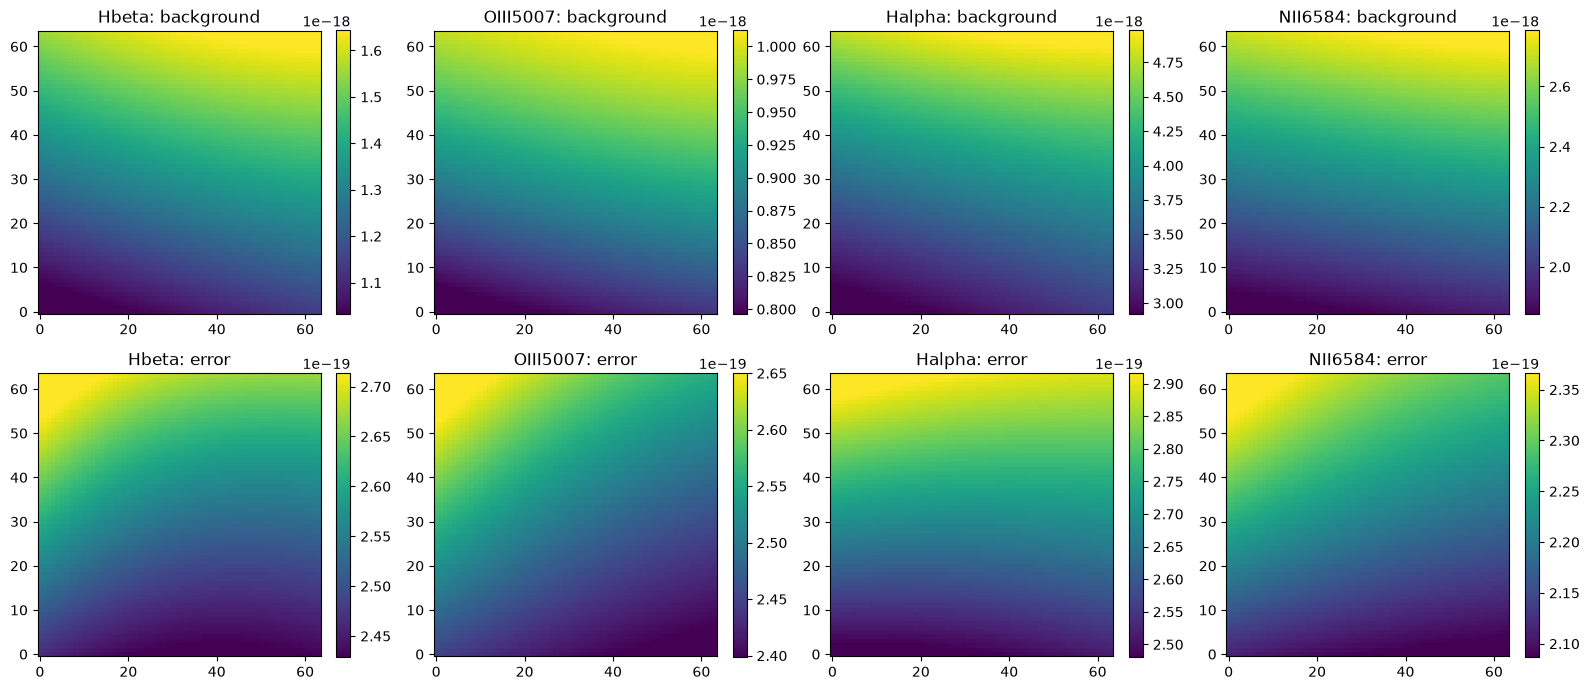

In [9]:
# ============================================================
# Inspect one background crop
# ============================================================

background_rng = np.random.default_rng(SEED)

example_background, example_error_maps, example_background_origin = extract_background_patch(
    rng=background_rng,
)

print("Example background origin (y, x):", example_background_origin)
print("Background shape:", example_background.shape)
print("Error-map shape:", example_error_maps.shape)


fig, axes = plt.subplots(2, len(USED_LINES), figsize=(16, 7))

for channel, line_name in enumerate(USED_LINES):
    background_image = example_background[channel]
    error_image = example_error_maps[channel]

    bmin, bmax = np.percentile(background_image, [2, 98])
    emin, emax = np.percentile(error_image, [2, 98])

    im = axes[0, channel].imshow(
        background_image,
        origin="lower",
        vmin=bmin,
        vmax=bmax,
    )
    axes[0, channel].set_title(f"{line_name}: background")
    plt.colorbar(im, ax=axes[0, channel], fraction=0.046)

    im = axes[1, channel].imshow(
        error_image,
        origin="lower",
        vmin=emin,
        vmax=emax,
    )
    axes[1, channel].set_title(f"{line_name}: error")
    plt.colorbar(im, ax=axes[1, channel], fraction=0.046)

plt.tight_layout()
plt.savefig("pn??.png")
plt.show()


In [10]:
# ============================================================
# Noise model
# ============================================================

def add_noise_to_maps(clean_maps, error_maps, rng):
    """Add independent Gaussian noise using the per-pixel line-error maps."""

    if clean_maps.shape != error_maps.shape:
        raise ValueError("clean_maps and error_maps must have the same shape.")

    standard_normal = rng.standard_normal(clean_maps.shape).astype(np.float32)

    return (
        clean_maps.astype(np.float32, copy=False)
        + standard_normal * error_maps.astype(np.float32, copy=False)
    ).astype(np.float32)


In [11]:
# ============================================================
# Optional fixed background
# ============================================================

fixed_background = None
fixed_error_maps = None
fixed_background_origin = None

if not REGENERATE_BACKGROUND_PER_SAMPLE:
    fixed_rng = np.random.default_rng(SEED)

    fixed_background, fixed_error_maps, fixed_background_origin = extract_background_patch(
        rng=fixed_rng,
    )

    print("Fixed background origin (y, x):", fixed_background_origin)


## Create one training sample

The background crop and its error crop come from the same spatial location. The PN signal is injected into the clean diffuse background first; noise is then drawn independently for each pixel from the matching four-channel error maps.


In [12]:
def create_training_sample(
    pn_models,
    hii_models,
    snr_models,
    rng,
    fixed_background=None,
    fixed_error_maps=None,
    fixed_background_origin=None,
):
    if REGENERATE_BACKGROUND_PER_SAMPLE:
        background_maps, error_maps, background_origin = extract_background_patch(
            rng=rng,
        )
    else:
        if fixed_background is None or fixed_error_maps is None:
            raise ValueError(
                "fixed_background and fixed_error_maps must be provided when "
                "REGENERATE_BACKGROUND_PER_SAMPLE is False."
            )

        background_maps = fixed_background.copy()
        error_maps = fixed_error_maps.copy()
        background_origin = fixed_background_origin

    group_id = background_group_from_origin(background_origin)

    if group_id is None:
        raise RuntimeError(
            f"Background patch {background_origin} is not assigned to a "
            "leakage-safe spatial group."
        )

    pn_only_maps = np.zeros_like(background_maps, dtype=np.float32)
    hii_only_maps = np.zeros_like(background_maps, dtype=np.float32)
    snr_only_maps = np.zeros_like(background_maps, dtype=np.float32)

    n_pn = int(rng.choice(PN_NUMBERS, p=PN_PROBABILITIES))
    n_hii = int(rng.choice(HII_NUMBERS, p=HII_PROBABILITIES))
    n_snr = int(rng.choice(SNR_NUMBERS, p=SNR_PROBABILITIES))

    if n_pn > 0:
        sample_type = "pn"
    elif n_hii > 0 or n_snr > 0:
        sample_type = "compact_nonpn"
    else:
        sample_type = "background"

    crowded_patch = bool(rng.random() < CROWDED_PATCH_PROBABILITY)

    if crowded_patch:
        separation_range = CROWDED_SOURCE_SEPARATION_RANGE_PIX
    else:
        separation_range = NORMAL_SOURCE_SEPARATION_RANGE_PIX

    minimum_separation_pix = float(rng.uniform(*separation_range))
    pn_pn_minimum_separation_pix = max(
        minimum_separation_pix,
        PN_PN_MIN_SEPARATION_PIX,
    )

    pn_positions, hii_positions, snr_positions = choose_typed_source_positions(
        n_pn=n_pn,
        n_hii=n_hii,
        n_snr=n_snr,
        patch_size=PATCH_SIZE,
        margin_pix=SOURCE_MARGIN_PIX,
        minimum_separation_pix=minimum_separation_pix,
        pn_pn_minimum_separation_pix=pn_pn_minimum_separation_pix,
        rng=rng,
    )

    n_all_sources = n_pn + n_hii + n_snr

    # One shared base observational PSF is sampled per patch.
    base_psf_fwhm_arcsec = None
    base_psf_fwhm_pix = None

    if n_all_sources > 0:
        base_psf_fwhm_arcsec = sample_truncated_normal(
            rng=rng,
            mean=PSF_FWHM_MEAN_ARCSEC,
            standard_deviation=PSF_FWHM_STD_ARCSEC,
            limits=PSF_FWHM_LIMITS_ARCSEC,
        )

        base_psf_fwhm_pix = base_psf_fwhm_arcsec / PIXEL_SCALE_ARCSEC

    pn_sources = []
    hii_sources = []
    snr_sources = []

    # -------------------------
    # Inject PNe: always unresolved relative to the sampled observational PSF.
    # -------------------------
    for position in pn_positions:
        model_index = int(rng.integers(0, len(pn_models)))
        model_row = pn_models.iloc[model_index]

        source_metadata = inject_psf_model_source(
            output_maps=pn_only_maps,
            model_row=model_row,
            position=position,
            source_class="PN",
            base_psf_fwhm_arcsec=base_psf_fwhm_arcsec,
            base_psf_fwhm_pix=base_psf_fwhm_pix,
            fwhm_scale=1.0,
            rng=rng,
        )
        pn_sources.append(source_metadata)

    # -------------------------
    # Inject HII distractors: unresolved/broadened FWHM mixture.
    # -------------------------
    for position in hii_positions:
        model_index = int(rng.integers(0, len(hii_models)))
        model_row = hii_models.iloc[model_index]

        source_metadata = inject_psf_model_source(
            output_maps=hii_only_maps,
            model_row=model_row,
            position=position,
            source_class="HII",
            base_psf_fwhm_arcsec=base_psf_fwhm_arcsec,
            base_psf_fwhm_pix=base_psf_fwhm_pix,
            fwhm_scale=sample_contaminant_fwhm_scale(rng),
            rng=rng,
        )
        hii_sources.append(source_metadata)

    # -------------------------
    # Inject SNR distractors: unresolved/broadened FWHM mixture.
    # -------------------------
    for position in snr_positions:
        model_index = int(rng.integers(0, len(snr_models)))
        model_row = snr_models.iloc[model_index]

        source_metadata = inject_psf_model_source(
            output_maps=snr_only_maps,
            model_row=model_row,
            position=position,
            source_class="SNR",
            base_psf_fwhm_arcsec=base_psf_fwhm_arcsec,
            base_psf_fwhm_pix=base_psf_fwhm_pix,
            fwhm_scale=sample_contaminant_fwhm_scale(rng),
            rng=rng,
        )
        snr_sources.append(source_metadata)

    distractor_only_maps = hii_only_maps + snr_only_maps
    all_source_maps = pn_only_maps + distractor_only_maps
    clean_injected_maps = background_maps + all_source_maps

    injected_maps = add_noise_to_maps(
        clean_maps=clean_injected_maps,
        error_maps=error_maps,
        rng=rng,
    )

    target = make_centre_heatmap(
        ny=PATCH_SIZE,
        nx=PATCH_SIZE,
        positions=pn_positions,
        sigma_pix=LABEL_SIGMA_PIX,
    )

    all_sources = pn_sources + hii_sources + snr_sources

    return {
        "background_maps": background_maps.astype(np.float32),
        "error_maps": error_maps.astype(np.float32),
        "pn_only_maps": pn_only_maps.astype(np.float32),
        "hii_only_maps": hii_only_maps.astype(np.float32),
        "snr_only_maps": snr_only_maps.astype(np.float32),
        "distractor_only_maps": distractor_only_maps.astype(np.float32),
        "all_source_maps": all_source_maps.astype(np.float32),
        "injected_maps": injected_maps.astype(np.float32),
        "target": target[None, :, :].astype(np.float32),
        "metadata": {
            "sample_type": sample_type,
            "group_id": group_id,

            # Compatibility aliases used by existing plotting code.
            "n_sources": int(n_pn),
            "sources": pn_sources,

            "n_pn": int(n_pn),
            "n_hii": int(n_hii),
            "n_snr": int(n_snr),

            "crowded_patch": crowded_patch,
            "minimum_source_separation_pix": float(minimum_separation_pix),
            "minimum_pn_pn_separation_pix": float(
                pn_pn_minimum_separation_pix
            ),

            "background_origin_yx": (
                None
                if background_origin is None
                else [int(background_origin[0]), int(background_origin[1])]
            ),
            "base_psf_fwhm_arcsec": (
                None
                if base_psf_fwhm_arcsec is None
                else float(base_psf_fwhm_arcsec)
            ),
            "base_psf_fwhm_pix": (
                None
                if base_psf_fwhm_pix is None
                else float(base_psf_fwhm_pix)
            ),

            "label_sigma_pix": float(LABEL_SIGMA_PIX),
            "spectral_scatter_dex": float(SPECTRAL_SCATTER_DEX),

            "pn_sources": pn_sources,
            "hii_sources": hii_sources,
            "snr_sources": snr_sources,
            "all_sources": all_sources,
        },
    }


In [13]:
sample_rng = np.random.default_rng(90)

example = create_training_sample(
    pn_models=pn_models,
    hii_models=hii_models,
    snr_models=snr_models,
    rng=sample_rng,
    fixed_background=fixed_background,
    fixed_error_maps=fixed_error_maps,
    fixed_background_origin=fixed_background_origin,
)

print("Background shape:", example["background_maps"].shape)
print("Error-map shape: ", example["error_maps"].shape)
print("Injected shape:  ", example["injected_maps"].shape)
print("Target shape:    ", example["target"].shape)
print("Background origin (y, x):", example["metadata"]["background_origin_yx"])
print("Group ID:", example["metadata"]["group_id"])
print("Sample type:", example["metadata"]["sample_type"])
print()
print(
    "Counts: "
    f"PN={example['metadata']['n_pn']}, "
    f"HII={example['metadata']['n_hii']}, "
    f"SNR={example['metadata']['n_snr']}"
)
print(
    "Sampled minimum separation [pix]:",
    example["metadata"]["minimum_source_separation_pix"],
)


Background shape: (4, 64, 64)
Error-map shape:  (4, 64, 64)
Injected shape:   (4, 64, 64)
Target shape:     (1, 64, 64)
Background origin (y, x): [1070, 3411]
Group ID: NGC253_background_and_errors_r004_c013
Sample type: pn

Counts: PN=1, HII=1, SNR=1
Sampled minimum separation [pix]: 6.253905171836427


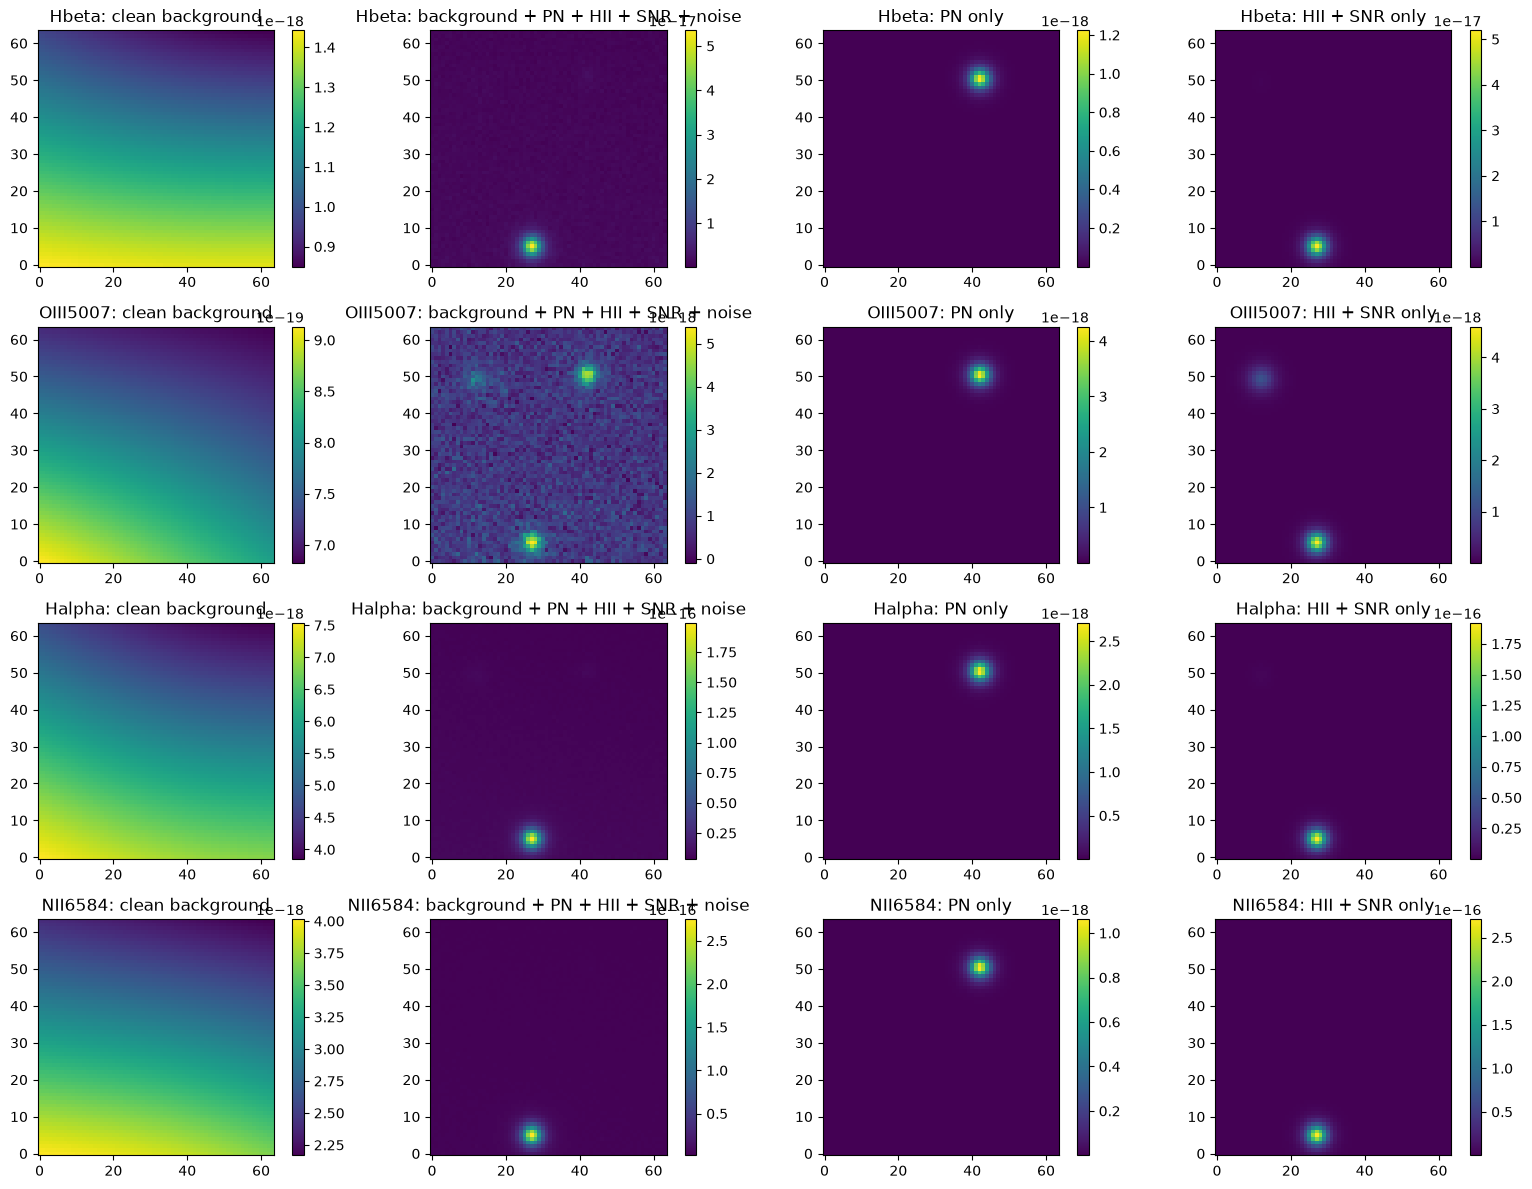

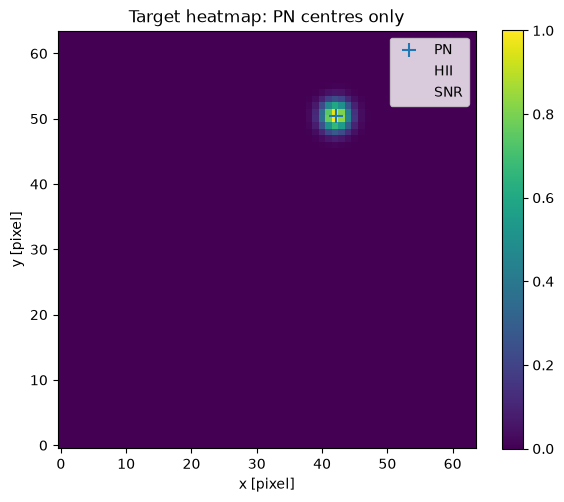

In [14]:
# Compare background, noisy injected map, PN signal, and distractor signal.

fig, axes = plt.subplots(
    len(USED_LINES),
    4,
    figsize=(16, 3 * len(USED_LINES)),
)

for channel, line_name in enumerate(USED_LINES):
    background = example["background_maps"][channel]
    injected = example["injected_maps"][channel]
    pn_only = example["pn_only_maps"][channel]
    distractor_only = example["distractor_only_maps"][channel]

    im0 = axes[channel, 0].imshow(background, origin="lower")
    axes[channel, 0].set_title(f"{line_name}: clean background")
    plt.colorbar(im0, ax=axes[channel, 0], fraction=0.046)

    im1 = axes[channel, 1].imshow(injected, origin="lower")
    axes[channel, 1].set_title(f"{line_name}: background + PN + HII + SNR + noise")
    plt.colorbar(im1, ax=axes[channel, 1], fraction=0.046)

    im2 = axes[channel, 2].imshow(pn_only, origin="lower")
    axes[channel, 2].set_title(f"{line_name}: PN only")
    plt.colorbar(im2, ax=axes[channel, 2], fraction=0.046)

    im3 = axes[channel, 3].imshow(distractor_only, origin="lower")
    axes[channel, 3].set_title(f"{line_name}: HII + SNR only")
    plt.colorbar(im3, ax=axes[channel, 3], fraction=0.046)
plt.savefig("pn?.png")
plt.tight_layout()
plt.show()


# Show that only PN positions appear in the target.
plt.figure(figsize=(6, 5))
plt.imshow(
    example["target"][0],
    origin="lower",
    vmin=0,
    vmax=1,
)

for source in example["metadata"]["pn_sources"]:
    plt.scatter(
        source["x"],
        source["y"],
        marker="+",
        s=90,
        label="PN" if "PN" not in plt.gca().get_legend_handles_labels()[1] else None,
    )

for source in example["metadata"]["hii_sources"]:
    plt.scatter(
        source["x"],
        source["y"],
        marker="o",
        facecolors="none",
        s=70,
        label="HII" if "HII" not in plt.gca().get_legend_handles_labels()[1] else None,
    )

for source in example["metadata"]["snr_sources"]:
    plt.scatter(
        source["x"],
        source["y"],
        marker="s",
        facecolors="none",
        s=70,
        label="SNR" if "SNR" not in plt.gca().get_legend_handles_labels()[1] else None,
    )

plt.title("Target heatmap: PN centres only")
plt.xlabel("x [pixel]")
plt.ylabel("y [pixel]")
plt.colorbar()
#plt.savefig("pn???.png")

handles, labels = plt.gca().get_legend_handles_labels()
if handles:
    plt.legend()

plt.tight_layout()
plt.show()


In [15]:
# ============================================================
# Dataset generation
# ============================================================

def create_dataset(
    n_samples,
    pn_models,
    hii_models,
    snr_models,
    seed,
    fixed_background=None,
    fixed_error_maps=None,
    fixed_background_origin=None,
    return_oiii_pn_only=False,
):
    rng = np.random.default_rng(seed)

    inputs = np.empty(
        (
            n_samples,
            len(USED_LINES),
            PATCH_SIZE,
            PATCH_SIZE,
        ),
        dtype=np.float32,
    )

    targets = np.empty(
        (
            n_samples,
            1,
            PATCH_SIZE,
            PATCH_SIZE,
        ),
        dtype=np.float32,
    )

    oiii_pn_only = None

    if return_oiii_pn_only:
        oiii_pn_only = np.empty(
            (n_samples, PATCH_SIZE, PATCH_SIZE),
            dtype=np.float32,
        )
        oiii_channel = USED_LINES.index("OIII5007")

    metadata = []
    sample_types = []
    group_ids = []

    for sample_index in range(n_samples):
        sample = create_training_sample(
            pn_models=pn_models,
            hii_models=hii_models,
            snr_models=snr_models,
            rng=rng,
            fixed_background=fixed_background,
            fixed_error_maps=fixed_error_maps,
            fixed_background_origin=fixed_background_origin,
        )

        inputs[sample_index] = sample["injected_maps"]
        targets[sample_index] = sample["target"]

        sample_metadata = sample["metadata"]
        metadata.append(sample_metadata)
        sample_types.append(sample_metadata["sample_type"])
        group_ids.append(sample_metadata["group_id"])

        if return_oiii_pn_only:
            oiii_pn_only[sample_index] = sample["pn_only_maps"][oiii_channel]

        if sample_index == 0 or (sample_index + 1) % 100 == 0:
            print(f"Generated {sample_index + 1}/{n_samples}")

    sample_types = np.asarray(sample_types, dtype="U32")
    group_ids = np.asarray(group_ids)

    if len(sample_types) != n_samples or len(group_ids) != n_samples:
        raise RuntimeError("sample_types/group_ids length does not match n_samples.")

    if return_oiii_pn_only:
        return (
            inputs,
            targets,
            metadata,
            sample_types,
            group_ids,
            oiii_pn_only,
        )

    return inputs, targets, metadata, sample_types, group_ids


def normalize_inputs_inplace(inputs, channel_means=None, channel_stds=None):
    """Standardize each emission-line channel over samples and spatial pixels.

    For validation or test data, pass the means and standard deviations computed
    from the training data instead of calculating new values.

    NOTE: The dataset generated below is normalized globally only for backwards
    compatibility with the existing saved-file format. The revised U-Net notebook
    detects this, inverts it, performs the group split, and recomputes normalization
    from training groups only.
    """

    if inputs.ndim != 4:
        raise ValueError("inputs must have shape (samples, channels, y, x).")

    n_channels = inputs.shape[1]

    if channel_means is None:
        channel_means = np.array(
            [
                np.mean(inputs[:, channel], dtype=np.float64)
                for channel in range(n_channels)
            ],
            dtype=np.float64,
        )
    else:
        channel_means = np.asarray(channel_means, dtype=np.float64)

    if channel_stds is None:
        channel_stds = np.array(
            [
                np.std(inputs[:, channel], dtype=np.float64)
                for channel in range(n_channels)
            ],
            dtype=np.float64,
        )
    else:
        channel_stds = np.asarray(channel_stds, dtype=np.float64)

    if channel_means.shape != (n_channels,):
        raise ValueError("channel_means must contain one value per channel.")

    if channel_stds.shape != (n_channels,):
        raise ValueError("channel_stds must contain one value per channel.")

    if np.any(~np.isfinite(channel_means)):
        raise ValueError("channel_means contains non-finite values.")

    if np.any(~np.isfinite(channel_stds)) or np.any(channel_stds <= 0):
        raise ValueError(
            "Every channel standard deviation must be finite and positive."
        )

    for channel in range(n_channels):
        np.subtract(
            inputs[:, channel],
            channel_means[channel],
            out=inputs[:, channel],
        )
        np.divide(
            inputs[:, channel],
            channel_stds[channel],
            out=inputs[:, channel],
        )

    return channel_means, channel_stds


In [16]:
# Generate the synthetic dataset.

(
    preview_X,
    preview_Y,
    preview_metadata,
    preview_sample_types,
    preview_group_ids,
    preview_oiii_pn_only,
) = create_dataset(
    n_samples=10000,
    pn_models=pn_models,
    hii_models=hii_models,
    snr_models=snr_models,
    seed=200,
    fixed_background=fixed_background,
    fixed_error_maps=fixed_error_maps,
    fixed_background_origin=fixed_background_origin,
    return_oiii_pn_only=True,
)

# ------------------------------------------------------------
# Audit sample composition before normalization
# ------------------------------------------------------------
print("X shape:", preview_X.shape)
print("Y shape:", preview_Y.shape)
print("X size [MB]:", preview_X.nbytes / 1024**2)

print("\nSample-type distribution:")
unique_types, type_counts = np.unique(preview_sample_types, return_counts=True)
for sample_type, count in zip(unique_types, type_counts):
    fraction = count / len(preview_sample_types)
    print(f"  {sample_type:15s}: {count:5d} ({100.0 * fraction:6.2f}%)")

negative_mask = preview_sample_types != "pn"
compact_negative_mask = preview_sample_types == "compact_nonpn"
background_negative_mask = preview_sample_types == "background"

if negative_mask.sum() == 0:
    raise RuntimeError("The generated dataset contains no PN-free negative samples.")

compact_fraction_among_negatives = (
    compact_negative_mask.sum() / negative_mask.sum()
)

print(
    "\nCompact non-PN fraction among all PN-free negatives: "
    f"{compact_fraction_among_negatives:.3f}"
)

if compact_fraction_among_negatives < 0.5:
    print(
        "WARNING: most negatives are pure background. Increase the HII/SNR "
        "distractor probabilities so realistic compact non-PN negatives dominate."
    )
else:
    print(
        "Good: realistic compact HII/SNR negatives are the majority of the "
        "PN-free negative pool."
    )

unique_groups, group_counts = np.unique(preview_group_ids, return_counts=True)
print("\nUnique spatial groups used:", len(unique_groups))
print(
    "Samples/group: min=", group_counts.min(),
    "median=", float(np.median(group_counts)),
    "max=", group_counts.max(),
)

if len(unique_groups) < 3:
    raise RuntimeError(
        "The generated dataset has fewer than three unique group_ids. "
        "A leakage-safe train/validation/test split is impossible."
    )

# ------------------------------------------------------------
# Compatibility normalization
# ------------------------------------------------------------
# The revised U-Net notebook will invert this global transform, split by
# preview_group_ids, and calculate the final normalization from TRAIN groups only.
preview_channel_means, preview_channel_stds = normalize_inputs_inplace(preview_X)

print("\nSaved compatibility-normalization statistics:")
for line_name, mean, std in zip(
    USED_LINES,
    preview_channel_means,
    preview_channel_stds,
):
    print(f"{line_name:10s}: mean={mean:.4e}, std={std:.4e}")


Generated 1/10000
Generated 100/10000
Generated 200/10000
Generated 300/10000
Generated 400/10000
Generated 500/10000
Generated 600/10000
Generated 700/10000
Generated 800/10000
Generated 900/10000
Generated 1000/10000
Generated 1100/10000
Generated 1200/10000
Generated 1300/10000
Generated 1400/10000
Generated 1500/10000
Generated 1600/10000
Generated 1700/10000
Generated 1800/10000
Generated 1900/10000
Generated 2000/10000
Generated 2100/10000
Generated 2200/10000
Generated 2300/10000
Generated 2400/10000
Generated 2500/10000
Generated 2600/10000
Generated 2700/10000
Generated 2800/10000
Generated 2900/10000
Generated 3000/10000
Generated 3100/10000
Generated 3200/10000
Generated 3300/10000
Generated 3400/10000
Generated 3500/10000
Generated 3600/10000
Generated 3700/10000
Generated 3800/10000
Generated 3900/10000
Generated 4000/10000
Generated 4100/10000
Generated 4200/10000
Generated 4300/10000
Generated 4400/10000
Generated 4500/10000
Generated 4600/10000
Generated 4700/10000
Gene

## Inspect normalized examples

Samples containing PNe: 5043


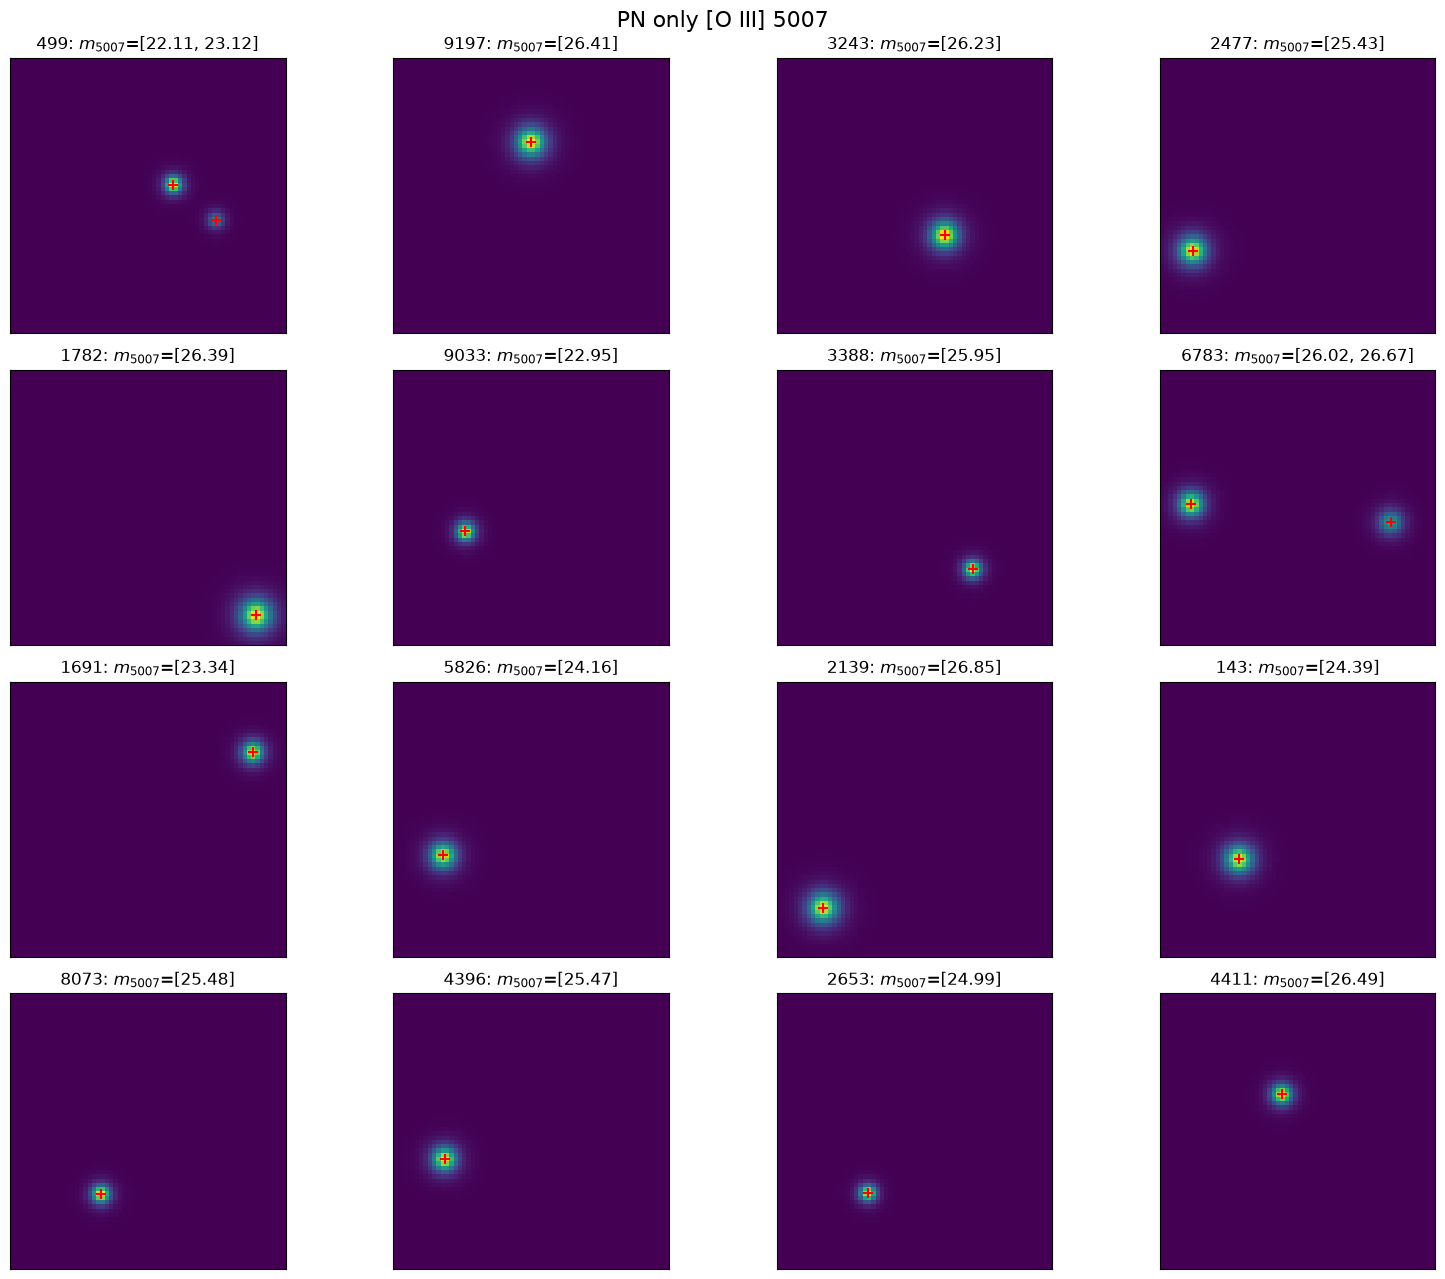

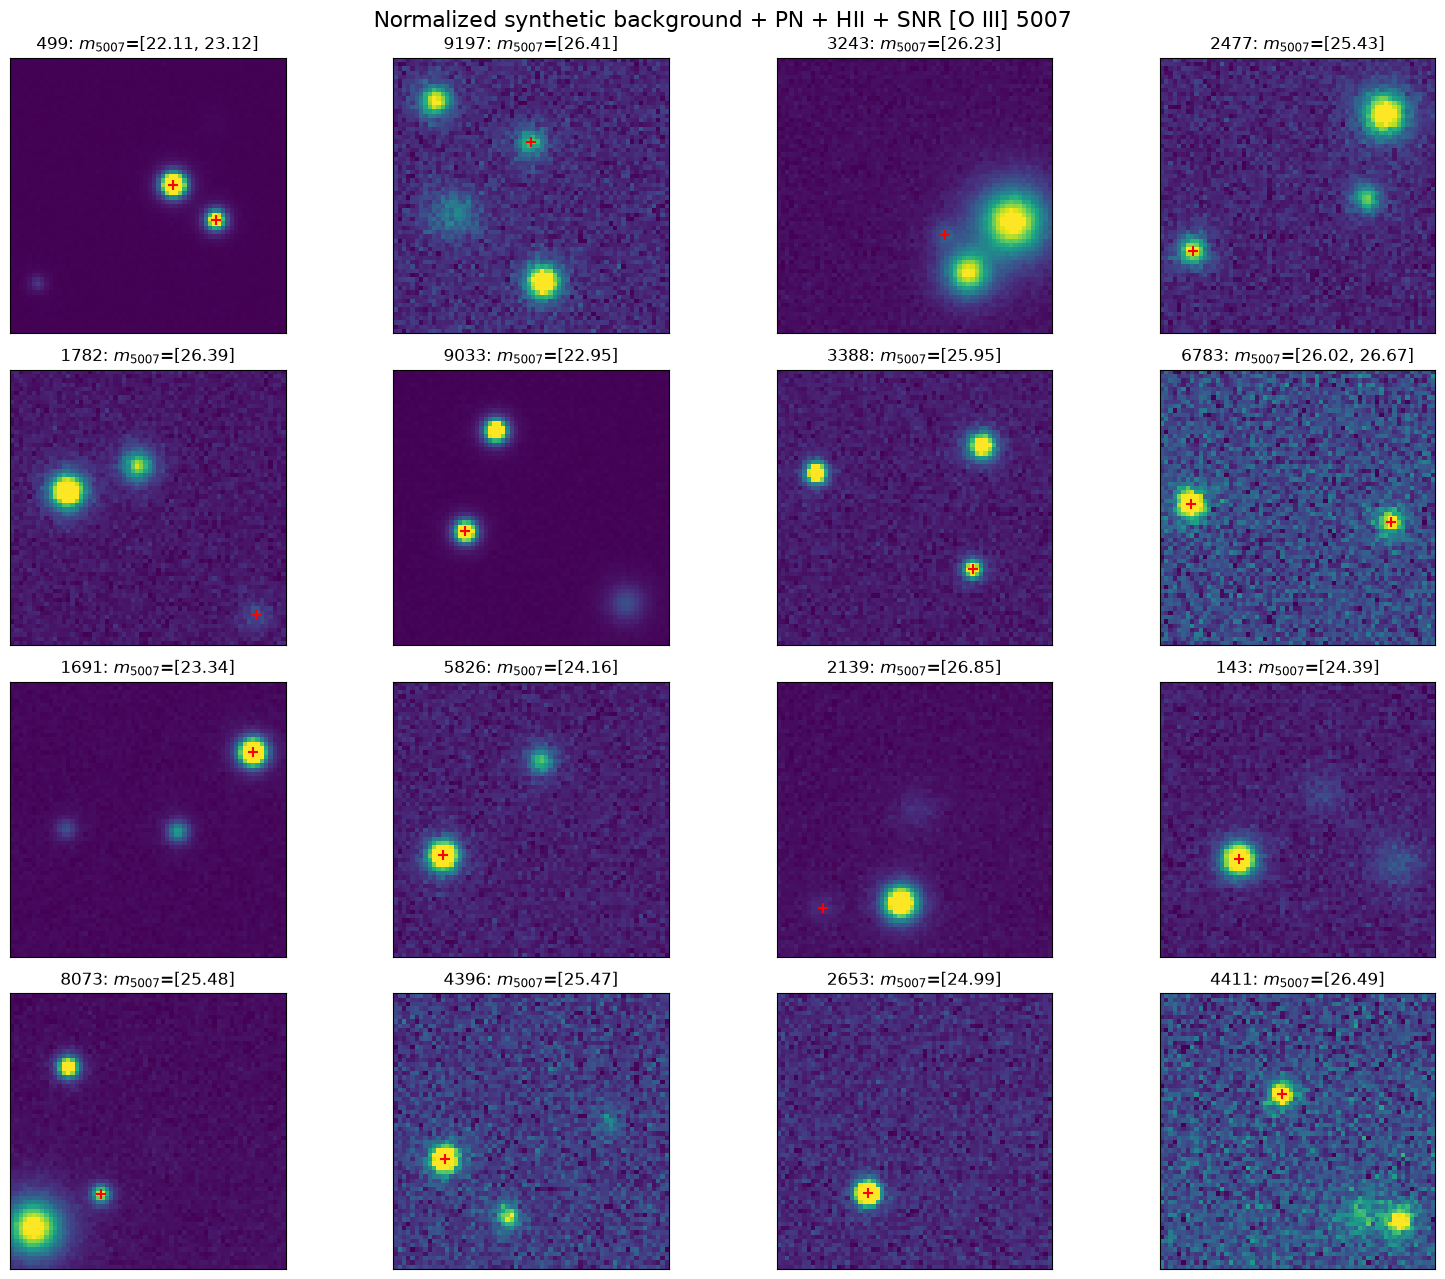

In [17]:
n_show = min(10, len(preview_X))

oiii_channel = USED_LINES.index("OIII5007")

plot_rng = np.random.default_rng(33)
# Indices of samples containing at least one PN
pn_sample_indices = np.array([
    i
    for i, metadata in enumerate(preview_metadata)
    if len(metadata["sources"]) > 0
])

n_show = min(16, len(pn_sample_indices))

plot_rng = np.random.default_rng(123)

sample_indices = plot_rng.choice(
    pn_sample_indices,
    size=n_show,
    replace=False,
)

print(f"Samples containing PNe: {len(pn_sample_indices)}")

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 13),
)

axes = axes.ravel()

for axis, sample_index in zip(
    axes,
    sample_indices,
):
    oiii_pn_only = preview_oiii_pn_only[sample_index]
    sources = preview_metadata[sample_index]["sources"]

    im = axis.imshow(
        oiii_pn_only,
        origin="lower",
        vmin=0.0,
        vmax=np.max(oiii_pn_only),
    )

    for source in sources:
        axis.scatter(
            source["x"],
            source["y"],
            marker="+",
            color="r",
            s=50,
            linewidths=1.5,
        )

    magnitudes = ", ".join(f'{source["m5007"]:.2f}' for source in sources)
    axis.set_title(f'{sample_index}: $m_{{5007}}$=[{magnitudes}]')
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle("PN only [O III] 5007", fontsize=16)
plt.tight_layout()
plt.savefig('pn1')
plt.show()

# ============================================================
# Plot the same [O III] background + PN maps
# ============================================================

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 13),
)

axes = axes.ravel()

for axis, sample_index in zip(
    axes,
    sample_indices,
):
    oiii_with_background = preview_X[
        sample_index,
        oiii_channel,
    ]

    sources = preview_metadata[sample_index]["sources"]

    vmin = np.percentile(
        oiii_with_background,
        1,
    )

    vmax = np.percentile(
        oiii_with_background,
        99.5,
    )

    im = axis.imshow(
        oiii_with_background,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    for source in sources:
        axis.scatter(
            source["x"],
            source["y"],
            marker="+",
            color="r",
            s=50,
            linewidths=1.5,
        )

    magnitudes = ", ".join(f'{source["m5007"]:.2f}' for source in sources)
    axis.set_title(f'{sample_index}: $m_{{5007}}$=[{magnitudes}]')
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle(
    "Normalized synthetic background + PN + HII + SNR [O III] 5007",
    fontsize=16,
)

plt.tight_layout()
plt.savefig('pn2')
plt.show()

## Save the dataset

The saved `.npz` now contains `sample_types` and `group_ids` in addition to the
original arrays. Use `group_ids` for the train/validation/test split and use
`sample_types` to report false positives separately on compact non-PN negatives
and pure-background negatives.


In [18]:
def save_dataset(
    output_path,
    inputs,
    targets,
    metadata,
    sample_types,
    group_ids,
    channel_means,
    channel_stds,
):
    output_path = Path(output_path)

    sample_types = np.asarray(sample_types, dtype="U32")
    group_ids = np.asarray(group_ids)

    if len(sample_types) != len(inputs):
        raise ValueError("sample_types must contain one value per input sample.")

    if len(group_ids) != len(inputs):
        raise ValueError("group_ids must contain one value per input sample.")

    np.savez_compressed(
        output_path,
        X=inputs,
        Y=targets,
        sample_types=sample_types,
        group_ids=group_ids,
        line_names=np.asarray(USED_LINES),
        channel_means=np.asarray(channel_means, dtype=np.float64),
        channel_stds=np.asarray(channel_stds, dtype=np.float64),
        metadata_json=np.asarray(json.dumps(metadata)),
    )

    print("Saved:", output_path.resolve())
    print("Saved sample_types:", np.unique(sample_types, return_counts=True))
    print("Saved unique group_ids:", len(np.unique(group_ids)))


save_dataset(
    output_path=OUTPUT_DATASET,
    inputs=preview_X,
    targets=preview_Y,
    metadata=preview_metadata,
    sample_types=preview_sample_types,
    group_ids=preview_group_ids,
    channel_means=preview_channel_means,
    channel_stds=preview_channel_stds,
)


Saved: /Users/golta/Desktop/Uni/Thesis/PN Detection/Synthesizer/all_PN_10000_grouped_norm_v5.0.npz
Saved sample_types: (array(['background', 'compact_nonpn', 'pn'], dtype='<U32'), array([ 334, 4623, 5043]))
Saved unique group_ids: 139
